# CreditParity – Step 5
**BUS/FIN 241A · Final Team Project · Profitable, Fair Lending Decisions**

**Step 5:** Threshold optimization and the three-zone decision policy

## Step 5 · Threshold Optimization and Decision Policy

**Which model?** The fairness analysis in Step 6 shows that the logistic regression with all features declines almost all creditworthy applicants aged 51+. CreditParity promises fair lending decisions, so its **final model is (c): a logistic regression trained with reweighing** on age group, sex and foreign worker status (details and the fairness comparison are in Step 6). The model with all features, **(a)**, stays in this notebook as the comparison model, to show the *price of fairness*. Both are explainable logistic regressions with the same preprocessing.

**Goal.** Decide what to do with the default probability (PD) of model (c):
- **a)** Find the cost-optimal threshold based on the 5:1 cost matrix and compare it with the default threshold of 0.5.
- **b)** Organize the decisions in three zones: 🟢 auto-approve, 🟡 manual review, 🔴 decline recommended. The upper boundary follows a **precision rule**: automatic declines must be correct in at least 80% of cases.
- **c)** Choose every threshold with **cross-validation on the training set** and use the test set **only once**, for the final evaluation.

**How we avoid overfitting the thresholds.** We create *out-of-fold* predictions for the 4,000 training applications: each application is scored by a model trained on the other four folds (5-fold stratified CV, the same folds as in Steps 4 and 6). For model (c), the reweighing weights are computed on the training part of each fold only.

**Cost assumption.** A missed default (FN) costs 5, a rejected good customer (FP) costs 1. This is the classic assumption for this dataset, not an estimate from real loss data.

In [1]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score, precision_score, confusion_matrix, roc_auc_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
ZONE_COLORS = {"Green": "#55A868", "Yellow": "#DDAA33", "Red": "#C44E52"}

COST_FN = 5                  # missed default
COST_FP = 1                  # rejected good customer
TARGET_PRECISION = 0.80      # automatic declines must be actual defaults in >= 80% of cases

In [2]:
# Load data
# In the repo the file lives in data/. In Google Colab, upload the CSV via the
# folder icon on the left and set DATA_PATH = "german_credit_data_biased_training.csv"
DATA_PATH = "../data/german_credit_data_biased_training.csv"
df = pd.read_csv(DATA_PATH)
df["y"] = (df["Risk"] == "Risk").astype(int)

X = df.drop(columns=["Risk", "y"])
y = df["y"]
categorical = X.select_dtypes(include=["object", "string"]).columns.tolist()
numeric = X.select_dtypes(include="number").columns.tolist()

# Same stratified 80/20 split as in Steps 3, 4 and 6
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

In [3]:
def make_model():
    """Logistic regression with one-hot encoding and standardization (same for (a) and (c))."""
    return Pipeline([
        ("prep", ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
            ("num", StandardScaler(), numeric)])),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ])

def age_group(data):
    return pd.cut(data["Age"], [18, 25, 35, 50, 100],
                  labels=["19-25", "26-35", "36-50", "51+"]).astype(str)

def reweighing_weights(data, y_true):
    """Kamiran & Calders reweighing on age group x sex x foreign worker status:
    weight = P(group) * P(y) / P(group, y), so that default is independent of the group
    in the weighted training data."""
    group = age_group(data) + "|" + data["Sex"] + "|" + data["ForeignWorker"]
    w = pd.Series(1.0, index=data.index)
    for g in group.unique():
        for label in [0, 1]:
            m = (group == g) & (y_true == label)
            if m.any():
                w[m] = (group == g).mean() * (y_true == label).mean() / m.mean()
    return w.to_numpy()

def fit_model(data, y_true, reweigh):
    model = make_model()
    if reweigh:
        return model.fit(data, y_true, model__sample_weight=reweighing_weights(data, y_true))
    return model.fit(data, y_true)

MODELS = {"(c) Reweighing – final": True, "(a) All features – comparison": False}
FINAL, COMPARISON = list(MODELS)

# Out-of-fold default probabilities for the training set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
y_oof = y_train.to_numpy()
fold_id = np.empty(len(y_oof), dtype=int)
p_oof = {name: np.zeros(len(y_oof)) for name in MODELS}
for k, (tr, va) in enumerate(cv.split(X_train, y_train)):
    fold_id[va] = k
    for name, reweigh in MODELS.items():
        m = fit_model(X_train.iloc[tr], y_train.iloc[tr], reweigh)
        p_oof[name][va] = m.predict_proba(X_train.iloc[va])[:, 1]

for name in MODELS:
    print(f"{name:32s} out-of-fold ROC AUC {roc_auc_score(y_oof, p_oof[name]):.3f} | "
          f"mean PD {p_oof[name].mean():.3f} (observed default rate {y_oof.mean():.3f})")

(c) Reweighing – final           out-of-fold ROC AUC 0.807 | mean PD 0.333 (observed default rate 0.334)
(a) All features – comparison    out-of-fold ROC AUC 0.856 | mean PD 0.335 (observed default rate 0.334)


### a) The cost-optimal threshold

With a threshold *t*, every application with PD ≥ *t* is declined. The total cost is

$$\text{Cost}(t) = 5 \cdot \text{FN}(t) + 1 \cdot \text{FP}(t).$$

With perfectly calibrated probabilities, theory gives $t^* = \frac{1}{1+5} \approx 0.17$. We search the actual optimum on a grid of thresholds.

In [4]:
THRESHOLDS = np.round(np.arange(0.01, 1.00, 0.01), 2)

def single_threshold_metrics(p, y_true, t):
    """Decline if p >= t. Returns cost and standard metrics."""
    decline = p >= t
    fn = int(((~decline) & (y_true == 1)).sum())
    fp = int((decline & (y_true == 0)).sum())
    return {"Threshold": t,
            "Cost": COST_FN * fn + COST_FP * fp,
            "Cost per 100 applications": 100 * (COST_FN * fn + COST_FP * fp) / len(y_true),
            "Recall": recall_score(y_true, decline),
            "Precision": precision_score(y_true, decline, zero_division=0),
            "Approval rate": 1 - decline.mean(),
            "FN": fn, "FP": fp}

def cost_optimal_threshold(p, y_true):
    costs = [single_threshold_metrics(p, y_true, t)["Cost"] for t in THRESHOLDS]
    return float(THRESHOLDS[int(np.argmin(costs))])

cost_curves = {name: pd.DataFrame([single_threshold_metrics(p_oof[name], y_oof, t) for t in THRESHOLDS])
               for name in MODELS}
T_LOWER = {name: cost_optimal_threshold(p_oof[name], y_oof) for name in MODELS}
cc = cost_curves[FINAL]
near_opt = cc.loc[cc["Cost"] <= 1.02 * cc["Cost"].min(), "Threshold"]
print(f"Cost-optimal threshold, final model (c): {T_LOWER[FINAL]}")
print(f"Thresholds within 2% of the minimum cost: {near_opt.min()} to {near_opt.max()}")
print(f"Cost-optimal threshold, comparison model (a): {T_LOWER[COMPARISON]}")

Cost-optimal threshold, final model (c): 0.16
Thresholds within 2% of the minimum cost: 0.13 to 0.17
Cost-optimal threshold, comparison model (a): 0.11


In [5]:
# Is the optimum of model (c) stable across folds?
fold_opt = [{"Fold": k + 1,
             "Optimal threshold": cost_optimal_threshold(p_oof[FINAL][fold_id == k], y_oof[fold_id == k])}
            for k in range(5)]
pd.DataFrame(fold_opt).set_index("Fold").T

Fold,1,2,3,4,5
Optimal threshold,0.15,0.16,0.16,0.09,0.16


In [6]:
# Model (c) at 0.5, at the theoretical 1/6 and at its cost-optimal threshold; model (a) for comparison
rows = [("(c) Default threshold 0.5", FINAL, 0.5),
        ("(c) Theoretical 1/6", FINAL, round(1 / 6, 2)),
        ("(c) Cost-optimal (CV)", FINAL, T_LOWER[FINAL]),
        ("(a) Default threshold 0.5 – baseline", COMPARISON, 0.5),
        ("(a) Cost-optimal (CV) – comparison", COMPARISON, T_LOWER[COMPARISON])]
compare_single = pd.DataFrame([{"Rule": r, **single_threshold_metrics(p_oof[m], y_oof, t)}
                               for r, m, t in rows]).set_index("Rule")
compare_single.round(3)

,Threshold,Cost,Cost per 100 applications,Recall,Precision,Approval rate,FN,FP
Rule,,,,,,,,
(c) Default threshold 0.5,0.50,3457,86.425,0.529,0.694,0.745,629,312
(c) Theoretical 1/6,0.17,2101,52.525,0.896,0.460,0.349,139,1406
(c) Cost-optimal (CV),0.16,2067,51.675,0.907,0.456,0.335,124,1447
(a) Default threshold 0.5 – baseline,0.50,2865,71.625,0.616,0.733,0.719,513,300
(a) Cost-optimal (CV) – comparison,0.11,1762,44.050,0.952,0.469,0.322,64,1442


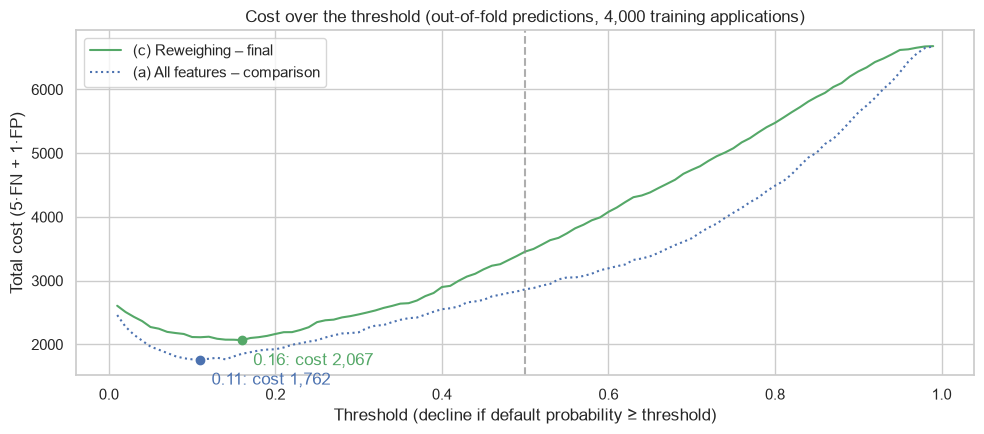

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for name, color, style in [(FINAL, "#55A868", "-"), (COMPARISON, "#4C72B0", ":")]:
    curve = cost_curves[name]
    ax.plot(curve["Threshold"], curve["Cost"], style, color=color, label=name)
    t = T_LOWER[name]
    c = curve.loc[curve["Threshold"] == t, "Cost"].iloc[0]
    ax.scatter([t], [c], color=color, zorder=5)
    ax.annotate(f"{t:.2f}: cost {c:,.0f}", (t, c), xytext=(8, -18), textcoords="offset points",
                color=color)
ax.axvline(0.5, ls="--", color="#8C8C8C", alpha=0.7)
ax.set_xlabel("Threshold (decline if default probability ≥ threshold)")
ax.set_ylabel("Total cost (5·FN + 1·FP)")
ax.set_title("Cost over the threshold (out-of-fold predictions, 4,000 training applications)")
ax.legend()
plt.tight_layout()
plt.show()

In [8]:
# Calibration of model (c) by probability band
bands = pd.cut(p_oof[FINAL], [0, 0.05, 0.1, 0.2, 0.3, 0.4, 0.6, 0.8, 1.0])
pd.DataFrame({"p": p_oof[FINAL], "y": y_oof}).groupby(bands, observed=True).agg(
    Applications=("y", "size"), Mean_predicted_PD=("p", "mean"),
    Observed_default_rate=("y", "mean")).round(3)

,Applications,Mean_predicted_PD,Observed_default_rate
"(0.0, 0.05]",457,0.027,0.024
"(0.05, 0.1]",415,0.076,0.104
"(0.1, 0.2]",702,0.146,0.178
"(0.2, 0.3]",563,0.249,0.258
"(0.3, 0.4]",458,0.348,0.323
"(0.4, 0.6]",681,0.492,0.455
"(0.6, 0.8]",452,0.696,0.681
"(0.8, 1.0]",272,0.874,0.904


**Result (a).** On the out-of-fold predictions, the cost-optimal threshold of the final model (c) is **0.16**:

| Rule (out-of-fold, 4,000 applications) | Threshold | Cost | Recall | Precision | Approval rate |
|---|---|---|---|---|---|
| (a) Baseline: all features, threshold 0.5 | 0.50 | 2,865 | 0.616 | 0.733 | 71.9% |
| (c) Default threshold | 0.50 | 3,457 | 0.529 | 0.694 | 74.5% |
| **(c) Cost-optimal (CV) – final** | **0.16** | **2,067** | **0.907** | 0.456 | 33.5% |
| (a) Cost-optimal (CV) – comparison | 0.11 | 1,762 | 0.952 | 0.469 | 32.2% |

- **The cost-based threshold is the main lever.** For model (c), moving from 0.5 to 0.16 cuts the cost from 3,457 to 2,067 (−40%) and raises recall from 53% to 91%. Compared with the baseline (all features, 0.5), the cost is 28% lower.
- **The price of fairness.** At their cost-optimal thresholds, the fair model (c) costs 2,067 and the comparison model (a) 1,762, i.e. 17% more. In return, the age gap for creditworthy applicants falls from 0.80 to 0.26 (Step 6).
- **Stable choice.** The cost curve is flat: all thresholds from 0.13 to 0.17 are within 2% of the minimum. Four of five folds give 0.15–0.16; one gives 0.09.
- **Calibration.** Model (c) is reasonably well calibrated (e.g. predicted 25%, observed 26% in the 0.2–0.3 band), close to the theoretical threshold of 1/6 ≈ 0.17.

### b) The three-zone policy

The cost-optimal threshold decides *whether* an application is approved. The three zones decide *who* makes the decision and *how* it is communicated:

| Zone | Rule | What happens |
|---|---|---|
| 🟢 Green – auto-approve | PD < lower boundary | Approved automatically |
| 🟡 Yellow – manual review | lower ≤ PD < upper | A credit analyst decides, supported by a SHAP explanation. **This is the only manual workload.** |
| 🔴 Red – decline recommended | PD ≥ upper boundary | The system declines and gives the customer a SHAP-based explanation of the main reasons. The customer can request a human review. |

**Why three zones?**
- **Human oversight.** The EU AI Act classifies credit scoring as a high-risk AI system and requires effective human oversight. Uncertain cases are decided by a person.
- **GDPR Art. 22.** Applicants have the right not to be subject to a purely automated decision with significant effects, and the right to obtain human intervention and to contest the decision. Every red-zone decline comes with an explanation and the option to request a human review.
- **Analyst workload.** Clear cases are handled automatically, so analysts can focus on the uncertain ones.

**The boundaries.**
- **Lower boundary = cost-optimal threshold** from part (a). The zones do not change *which* applications are approved automatically, so the cost and recall from part (a) still apply. All cost figures refer to this single-threshold logic.
- **Upper boundary = precision rule.** An automatic decline should rarely hit a good customer. We choose the **lowest threshold at which at least 80% of the applications in the red zone are actual defaults** (precision ≥ 80%). A higher target means fewer wrongful automatic declines, but more cases for the analysts.

In [9]:
def upper_for_precision(p, y_true, lower, target):
    """Lowest threshold >= lower at which the red zone (p >= threshold) has precision >= target."""
    for t in THRESHOLDS[THRESHOLDS >= lower]:
        red = p >= t
        if red.any() and y_true[red].mean() >= target:
            return float(t)
    return 1.0

def zone_of(p, lower, upper):
    return np.where(p < lower, "Green", np.where(p >= upper, "Red", "Yellow"))

def zone_table(p, y_true, lower, upper):
    """Share of applications, defaults and good customers per zone."""
    zone = zone_of(p, lower, upper)
    rows = []
    for z in ["Green", "Yellow", "Red"]:
        m = zone == z
        defaults = int((m & (y_true == 1)).sum())
        rows.append({"Zone": z, "Applications": int(m.sum()), "Share": m.mean(),
                     "Defaults": defaults, "Good customers": int(m.sum()) - defaults,
                     "Default rate": defaults / max(m.sum(), 1),
                     "Share of all defaults": defaults / max((y_true == 1).sum(), 1)})
    table = pd.DataFrame(rows).set_index("Zone")
    table.loc["Total"] = [len(y_true), 1.0, int(y_true.sum()), int((y_true == 0).sum()),
                          y_true.mean(), 1.0]
    return table.astype({"Applications": int, "Defaults": int, "Good customers": int})

def policy_summary(p, y_true, lower, upper):
    """Key figures of a zone policy."""
    zone = zone_of(p, lower, upper)
    red = zone == "Red"
    single = single_threshold_metrics(p, y_true, lower)
    return {"Lower": lower, "Upper": upper,
            "Green": (zone == "Green").mean(), "Yellow (manual review)": (zone == "Yellow").mean(),
            "Red": red.mean(),
            "Red precision": y_true[red].mean() if red.any() else np.nan,
            "Good customers auto-declined (red)": int((red & (y_true == 0)).sum()),
            "Good customers declined (PD ≥ lower)": single["FP"],
            "Defaults auto-approved (green)": single["FN"],
            "Cost (single threshold)": single["Cost"]}

TARGETS = [0.75, 0.80, 0.85, 0.90]
T_UPPER = {name: upper_for_precision(p_oof[name], y_oof, T_LOWER[name], TARGET_PRECISION)
           for name in MODELS}
for name in MODELS:
    print(f"{name:32s} green < {T_LOWER[name]:.2f} ≤ yellow < {T_UPPER[name]:.2f} ≤ red")

print(f"\nFinal model (c), out-of-fold – zones {T_LOWER[FINAL]} / {T_UPPER[FINAL]}")
zone_table(p_oof[FINAL], y_oof, T_LOWER[FINAL], T_UPPER[FINAL]).round(3)

(c) Reweighing – final           green < 0.16 ≤ yellow < 0.65 ≤ red
(a) All features – comparison    green < 0.11 ≤ yellow < 0.58 ≤ red

Final model (c), out-of-fold – zones 0.16 / 0.65


,Applications,Share,Defaults,Good customers,Default rate,Share of all defaults
Zone,,,,,,
Green,1341,0.335,124,1217,0.092,0.093
Yellow,2056,0.514,729,1327,0.355,0.546
Red,603,0.151,483,120,0.801,0.362
Total,4000,1.000,1336,2664,0.334,1.000


In [10]:
# Trade-off: target precision for automatic declines vs. manual review workload (out-of-fold)
def target_table(p_dict, y_true, uppers=None):
    rows = []
    for name in MODELS:
        for target in TARGETS:
            upper = (uppers[(name, target)] if uppers is not None
                     else upper_for_precision(p_dict[name], y_true, T_LOWER[name], target))
            rows.append({"Model": name, "Target precision": target,
                         **policy_summary(p_dict[name], y_true, T_LOWER[name], upper)})
    return pd.DataFrame(rows).set_index(["Model", "Target precision"])

targets_oof = target_table(p_oof, y_oof)
UPPERS_BY_TARGET = targets_oof["Upper"].to_dict()     # chosen on training data, reused on the test set
targets_oof[["Upper", "Green", "Yellow (manual review)", "Red", "Red precision",
             "Good customers auto-declined (red)"]].round(3)

Upper  Green  \
Model                         Target precision                 
(c) Reweighing – final        0.75               0.59  0.335   
                              0.80               0.65  0.335   
                              0.85               0.72  0.335   
                              0.90               0.80  0.335   
(a) All features – comparison 0.75               0.52  0.322   
                              0.80               0.58  0.322   
                              0.85               0.66  0.322   
                              0.90               0.73  0.322   

                                                Yellow (manual review)    Red  \
Model                         Target precision                                  
(c) Reweighing – final        0.75                               0.475  0.190   
                              0.80                               0.514  0.151   
                              0.85                               0.556  0.109   
                              0.90                               0.597  0.068   
(a) All features – comparison 0.75                               0.412  0.267   
                              0.80                               0.444  0.234   
                              0.85                               0.482  0.197   
                              0.90                               0.521  0.157   

                                                Red precision  \
Model                         Target precision                  
(c) Reweighing – final        0.75                      0.757   
                              0.80                      0.801   
                              0.85                      0.854   
                              0.90                      0.904   
(a) All features – comparison 0.75                      0.754   
                              0.80                      0.802   
                              0.85                      0.853   
                              0.90                      0.905   

                                                Good customers auto-declined (red)  
Model                         Target precision                                      
(c) Reweighing – final        0.75                                             184  
                              0.80                                             120  
                              0.85                                              64  
                              0.90                                              26  
(a) All features – comparison 0.75                                             263  
                              0.80                                             185  
                              0.85                                             116  
                              0.90                                              60

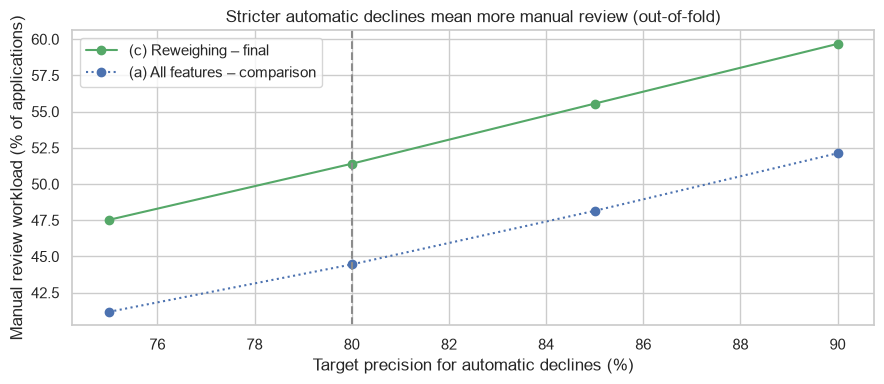

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
for name, color, style in [(FINAL, "#55A868", "-"), (COMPARISON, "#4C72B0", ":")]:
    d = targets_oof.loc[name]
    ax.plot(100 * d.index, 100 * d["Yellow (manual review)"], style, marker="o", color=color,
            label=name)
ax.axvline(100 * TARGET_PRECISION, ls="--", color="#8C8C8C")
ax.set_xlabel("Target precision for automatic declines (%)")
ax.set_ylabel("Manual review workload (% of applications)")
ax.set_title("Stricter automatic declines mean more manual review (out-of-fold)")
ax.legend()
plt.tight_layout()
plt.show()

In [12]:
# Stability of the boundaries of model (c) across folds
fold_rows = []
for k in range(5):
    m = fold_id == k
    lo = cost_optimal_threshold(p_oof[FINAL][m], y_oof[m])
    up = upper_for_precision(p_oof[FINAL][m], y_oof[m], lo, TARGET_PRECISION)
    zone = zone_of(p_oof[FINAL][m], lo, up)
    fold_rows.append({"Fold": k + 1, "Lower": lo, "Upper": up,
                      "Manual review": round((zone == "Yellow").mean(), 3)})
pd.DataFrame(fold_rows).set_index("Fold").T

Fold,1,2,3,4,5
Lower,0.150,0.160,0.160,0.090,0.160
Upper,0.660,0.690,0.640,0.600,0.660
Manual review,0.535,0.526,0.515,0.598,0.529


**Result (b).** With the precision rule (≥ 80%), the boundaries of the final model (c) are **0.16 and 0.65**:

| Zone (out-of-fold, model (c)) | Share | Defaults | Good customers | Default rate |
|---|---|---|---|---|
| 🟢 Green – auto-approve (PD < 0.16) | 33.5% | 124 | 1,217 | 9.2% |
| 🟡 Yellow – manual review (0.16 – 0.65) | 51.4% | 729 | 1,327 | 35.5% |
| 🔴 Red – decline recommended (PD ≥ 0.65) | 15.1% | 483 | 120 | 80.1% |

- **Automatic declines are reliable.** 80% of the applications in the red zone are actual defaults; only 120 good customers are declined automatically.
- **The price is a large manual workload.** Model (c) separates defaults and good customers less sharply than model (a), so the uncertain middle is wider: about half of all applications (51%) go to an analyst. With the same rule, model (a) would send 44% to manual review, but would also decline 185 good customers automatically instead of 120.
- **Trade-off with the target precision** (out-of-fold, model (c)):

| Target precision | Upper boundary | Manual review | Red zone | Good customers auto-declined |
|---|---|---|---|---|
| 75% | 0.59 | 47.5% | 19.0% | 184 |
| **80%** | **0.65** | **51.4%** | **15.1%** | **120** |
| 85% | 0.72 | 55.6% | 10.9% | 64 |
| 90% | 0.80 | 59.7% | 6.8% | 26 |

  Each step of 5 percentage points in the target moves about 4 percentage points of applications from automatic decline to manual review.
- **Stable.** Across the five folds, the upper boundary ranges from 0.60 to 0.69 and the manual review share from 51.5% to 59.8%.

### c) Final evaluation on the test set

Now – and only now – we use the test set. Both models are trained on all 4,000 training applications and the thresholds chosen above are applied **without any change** to the 1,000 test applications.

In [13]:
y_test_arr = y_test.to_numpy()
p_test = {name: fit_model(X_train, y_train, reweigh).predict_proba(X_test)[:, 1]
          for name, reweigh in MODELS.items()}

rows = [("(a) Default threshold 0.5 – baseline", COMPARISON, 0.5),
        ("(c) Default threshold 0.5", FINAL, 0.5),
        ("(c) Cost-optimal – final", FINAL, T_LOWER[FINAL]),
        ("(a) Cost-optimal – comparison", COMPARISON, T_LOWER[COMPARISON])]
test_single = pd.DataFrame([{"Rule": r, **single_threshold_metrics(p_test[m], y_test_arr, t)}
                            for r, m, t in rows]).set_index("Rule")
display(test_single.round(3))

for r, m, t in rows:
    tn, fp, fn, tp = confusion_matrix(y_test_arr, (p_test[m] >= t).astype(int)).ravel()
    print(f"{r:40s} TP {tp}, TN {tn}, FP {fp}, FN {fn}")

,Threshold,Cost,Cost per 100 applications,Recall,Precision,Approval rate,FN,FP
Rule,,,,,,,,
(a) Default threshold 0.5 – baseline,0.50,700,70.0,0.626,0.736,0.716,125,75
(c) Default threshold 0.5,0.50,863,86.3,0.530,0.694,0.745,157,78
(c) Cost-optimal – final,0.16,488,48.8,0.925,0.460,0.328,25,363
(a) Cost-optimal – comparison,0.11,409,40.9,0.958,0.486,0.341,14,339


(a) Default threshold 0.5 – baseline     TP 209, TN 591, FP 75, FN 125
(c) Default threshold 0.5                TP 177, TN 588, FP 78, FN 157
(c) Cost-optimal – final                 TP 309, TN 303, FP 363, FN 25
(a) Cost-optimal – comparison            TP 320, TN 327, FP 339, FN 14


In [14]:
# Zone policy on the test set (target precision 80%)
test_policy = pd.DataFrame({name: policy_summary(p_test[name], y_test_arr, T_LOWER[name], T_UPPER[name])
                            for name in MODELS})
display(test_policy.round(3))

print(f"Final model (c), test set – zones {T_LOWER[FINAL]} / {T_UPPER[FINAL]}")
test_zones = zone_table(p_test[FINAL], y_test_arr, T_LOWER[FINAL], T_UPPER[FINAL])
test_zones.round(3)

,(c) Reweighing – final,(a) All features – comparison
Lower,0.160,0.110
Upper,0.650,0.580
Green,0.328,0.341
Yellow (manual review),0.529,0.421
Red,0.143,0.238
Red precision,0.825,0.819
Good customers auto-declined (red),25.000,43.000
Good customers declined (PD ≥ lower),363.000,339.000
Defaults auto-approved (green),25.000,14.000
Cost (single threshold),488.000,409.000


Final model (c), test set – zones 0.16 / 0.65


,Applications,Share,Defaults,Good customers,Default rate,Share of all defaults
Zone,,,,,,
Green,328,0.328,25,303,0.076,0.075
Yellow,529,0.529,191,338,0.361,0.572
Red,143,0.143,118,25,0.825,0.353
Total,1000,1.000,334,666,0.334,1.000


In [15]:
# Target precision table on the test set (boundaries chosen on the training data)
targets_test = target_table(p_test, y_test_arr, uppers=UPPERS_BY_TARGET)
targets_test[["Upper", "Green", "Yellow (manual review)", "Red", "Red precision",
              "Good customers auto-declined (red)"]].round(3)

Upper  Green  \
Model                         Target precision                 
(c) Reweighing – final        0.75               0.59  0.328   
                              0.80               0.65  0.328   
                              0.85               0.72  0.328   
                              0.90               0.80  0.328   
(a) All features – comparison 0.75               0.52  0.341   
                              0.80               0.58  0.341   
                              0.85               0.66  0.341   
                              0.90               0.73  0.341   

                                                Yellow (manual review)    Red  \
Model                         Target precision                                  
(c) Reweighing – final        0.75                               0.489  0.183   
                              0.80                               0.529  0.143   
                              0.85                               0.567  0.105   
                              0.90                               0.600  0.072   
(a) All features – comparison 0.75                               0.391  0.268   
                              0.80                               0.421  0.238   
                              0.85                               0.461  0.198   
                              0.90                               0.504  0.155   

                                                Red precision  \
Model                         Target precision                  
(c) Reweighing – final        0.75                      0.781   
                              0.80                      0.825   
                              0.85                      0.857   
                              0.90                      0.917   
(a) All features – comparison 0.75                      0.757   
                              0.80                      0.819   
                              0.85                      0.859   
                              0.90                      0.910   

                                                Good customers auto-declined (red)  
Model                         Target precision                                      
(c) Reweighing – final        0.75                                              40  
                              0.80                                              25  
                              0.85                                              15  
                              0.90                                               6  
(a) All features – comparison 0.75                                              65  
                              0.80                                              43  
                              0.85                                              28  
                              0.90                                              14

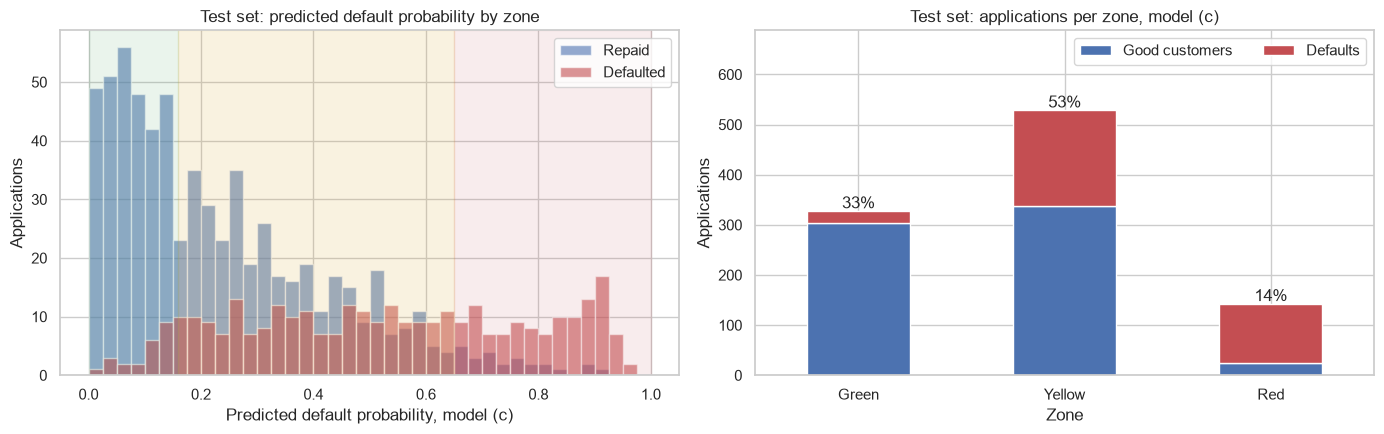

In [16]:
lo, up = T_LOWER[FINAL], T_UPPER[FINAL]
p, yt = p_test[FINAL], y_test_arr
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Left: distribution of default probabilities with the zone boundaries
bins = np.linspace(0, 1, 41)
axes[0].hist(p[yt == 0], bins=bins, alpha=0.6, label="Repaid", color="#4C72B0")
axes[0].hist(p[yt == 1], bins=bins, alpha=0.6, label="Defaulted", color="#C44E52")
axes[0].axvspan(0, lo, color=ZONE_COLORS["Green"], alpha=0.12)
axes[0].axvspan(lo, up, color=ZONE_COLORS["Yellow"], alpha=0.15)
axes[0].axvspan(up, 1, color=ZONE_COLORS["Red"], alpha=0.10)
axes[0].set_xlabel("Predicted default probability, model (c)")
axes[0].set_ylabel("Applications")
axes[0].set_title("Test set: predicted default probability by zone")
axes[0].legend()

# Right: composition of each zone
comp = test_zones.loc[["Green", "Yellow", "Red"], ["Good customers", "Defaults"]]
comp.plot.bar(stacked=True, color=["#4C72B0", "#C44E52"], ax=axes[1], rot=0)
axes[1].set_ylim(0, comp.sum(axis=1).max() * 1.3)
axes[1].legend(loc="upper right", ncol=2)
for i, z in enumerate(comp.index):
    axes[1].text(i, comp.loc[z].sum() + 5, f"{test_zones.loc[z, 'Share']:.0%}", ha="center")
axes[1].set_title("Test set: applications per zone, model (c)")
axes[1].set_ylabel("Applications")
plt.tight_layout()
plt.show()

**Result (c) – final evaluation on the test set (1,000 applications).**

**Headline: the cost-based threshold with the fair model.**

| Rule (test set) | Cost | Recall | Precision | TP | FN | FP | TN |
|---|---|---|---|---|---|---|---|
| (a) Baseline: all features, threshold 0.5 | 700 | 0.626 | 0.736 | 209 | 125 | 75 | 591 |
| **(c) Fair model, cost-optimal threshold 0.16** | **488 (−30%)** | **0.925** | 0.460 | 309 | 25 | 363 | 303 |
| (a) All features, cost-optimal 0.11 – comparison | 409 (−42%) | 0.958 | 0.486 | 320 | 14 | 339 | 327 |

With the fair model (c), the cost is still **about 30% lower than with the default threshold of 0.5** (488 vs. 700), and recall rises from 0.63 to 0.93. At the same time, the age gap for creditworthy applicants drops from 0.80 to 0.26 and the sex gap from 0.15 to 0.04 (Step 6), and the model remains an explainable logistic regression. 
**The price of fairness.** Compared with model (a), the fair model (c):
- costs **19% more** (488 vs. 409 on the test set), but is still **30% cheaper** than the default threshold of 0.5 (700);
- sends more applications to manual review (**53% vs. 42%**);
- auto-approves more defaults (**25 vs. 14**).

In return:
- **no creditworthy applicant aged 51+ is declined automatically** on the test set (0 of 21, vs. 8 of 21 with model (a); on the training data 5 of 83 vs. 41 of 83);
- the zone shares of women and men are almost identical (out-of-fold: green 36% vs. 32%, yellow 51% vs. 52%, red 13% vs. 16%);
- the age gap for creditworthy applicants (EOD) falls from 0.80 to 0.26 and the sex gap from 0.15 to 0.04.

**Zones on the test set (model (c), boundaries 0.16 / 0.65).**

| | Model (c) – final | Model (a) – comparison |
|---|---|---|
| Boundaries | 0.16 / 0.65 | 0.11 / 0.58 |
| 🟢 Auto-approve | 32.8% | 34.1% |
| 🟡 Manual review | 52.9% | 42.1% |
| 🔴 Decline recommended | 14.3% | 23.8% |
| Red-zone precision | 82.5% | 81.9% |
| Good customers declined automatically (red) | 25 | 43 |
| Good customers with PD ≥ lower boundary (yellow + red) | 363 | 339 |
| Defaults auto-approved (green) | 25 | 14 |
| Cost (single-threshold logic) | 488 | 409 |

| Target precision (test set, model (c)) | Upper boundary | Manual review | Red zone | Red precision | Good customers auto-declined |
|---|---|---|---|---|---|
| 75% | 0.59 | 48.9% | 18.3% | 78.1% | 40 |
| **80%** | **0.65** | **52.9%** | **14.3%** | **82.5%** | **25** |
| 85% | 0.72 | 56.7% | 10.5% | 85.7% | 15 |
| 90% | 0.80 | 60.0% | 7.2% | 91.7% | 6 |

The red-zone precision on the test set meets every target, and the test costs per 100 applications (48.8) are close to the out-of-fold value (51.7), so the thresholds were not overfitted.

**Decision for CreditParity.** Final model (c) (reweighing) with the cost-optimal threshold **0.16** as the green/yellow boundary and **0.65** (target precision 80%) as the yellow/red boundary. Model (a) is kept as the comparison model.

**Limitations.**
- The 80% precision target for automatic declines is a business assumption. Before deployment it should be validated with the bank's risk and compliance teams. In operation, the thresholds should be monitored regularly and adjusted to the available analyst capacity: a higher target reduces wrongful automatic declines but increases the manual review workload.
- With this target, about half of all applications (53% on the test set) go to manual review. This is a substantial workload and may require a lower target or more analysts.
- The 5:1 cost ratio is an assumption. A different ratio leads to a different lower boundary.
- The fair model auto-approves more defaults than model (a) (25 vs. 14 on the test set), because its lower boundary is higher (0.16 vs. 0.11) and it separates defaults from good customers less sharply.
- The cost figures assume that every application with PD ≥ 0.16 is declined. Analyst decisions in the yellow zone and human reviews requested in the red zone may change some of these decisions; the dataset cannot show how this affects cost.
- Reweighing uses protected attributes (age, sex, foreign worker status) during training, which needs a legal review. It also increases the decline rate of young good customers (see Step 6).
- The dataset is synthetic. The separation between defaults and good customers may differ in real loan data.